In [1]:
%pip install gwosc gwpy datasets huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from gwosc.datasets import find_datasets
from gwosc import datasets
from gwosc.datasets import event_gps
from warnings import catch_warnings
from gwpy.timeseries import TimeSeries
import requests
import huggingface_hub
from huggingface_hub import hf_hub_download

huggingface_hub.login('')

/opt/anaconda3/envs/isef26/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.utils.data as tdata
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from tqdm import tqdm
import random
import os
# from waveform_model import WaveformPredictor

if torch.cuda.is_available():
  device = torch.device('cuda')
elif torch.mps.is_available():
  device = torch.device('mps')
else:
  device = torch.device('cpu')


def set_seed(seed_value=42):
    random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)
        # torch.backends.cudnn.deterministic = True
        # torch.backends.cudnn.benchmark = False

    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed_value)

set_seed(42)

# Model train

In [4]:
from datasets import load_dataset

wave_dataset = load_dataset("Luca207/waveforms")['train']
wave_dataset = pd.DataFrame(wave_dataset)

In [5]:
#use mass_1_source','mass_2_source','final_mass_source', 'chi_eff', window_duration
# devide input by 1+redshift (training) and then multiply by it (prediction)
params_of_interest = ['mass_1_source','mass_2_source','final_mass_source','chi_eff'] # + 'redshift', 'time_window'

In [6]:
good_ids = np.linspace(0,len(wave_dataset)-1,len(wave_dataset)-1,dtype=np.int16)

for p in params_of_interest:
  good_ids = np.intersect1d(good_ids,np.where(wave_dataset[p].isna()==False)[0])

good_ids = np.intersect1d(good_ids,np.where(np.concatenate(wave_dataset['waveform']).reshape(len(wave_dataset['waveform']),-1).min(axis=1).astype(np.str_) !='nan'))

wave_dataset = wave_dataset.iloc[good_ids]

In [7]:
norm_parameters = {}

for param in params_of_interest+['waveform']:
    if param == 'waveform':
        arr1 = np.concatenate(np.array(wave_dataset[param])).reshape(-1, 1)
    else:
        arr1 = np.array(wave_dataset[param]).reshape(-1, 1)
    global_mean, global_std = arr1.mean(), arr1.std()
    norm_parameters[param] = (global_mean, global_std)

wave_dataset['waveform'] = list((np.stack(wave_dataset['waveform']) / (1+np.stack([wave_dataset['redshift']]).reshape(-1,1)) - norm_parameters['waveform'][0]) / norm_parameters['waveform'][1])
for param in params_of_interest:
    wave_dataset[param] = list((np.array(wave_dataset[param]-norm_parameters[param][0]) / norm_parameters[param][1]))


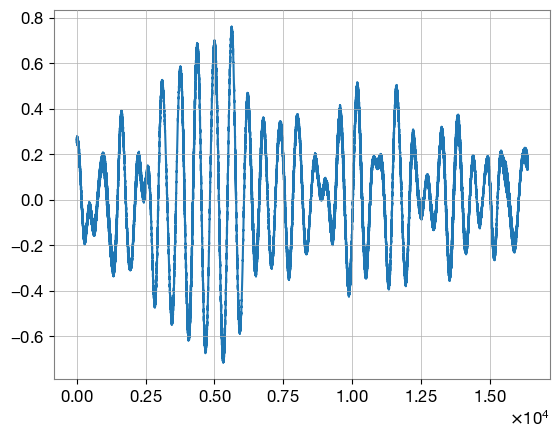

In [8]:
plt.plot(wave_dataset['waveform'][0])

In [9]:
class Dataset(tdata.Dataset):
    def __init__(self,wave_data,params_of_interest,device, max_seq_len, start_len = 0.01, end_len = 0.03, len_steps = 6):
        super().__init__()

        self.device = device
        self.param_data = []
        self.waveform_data = []
        self.masks = []

        for id in range(len(wave_data)):
            data = wave_data.iloc[id]
            for s_len in np.linspace(start_len,end_len,len_steps):
              start = int((data['time_window']/2 - s_len) * data['frequency'])
              end = int((data['time_window']/2 + s_len) * data['frequency'])
              end = min(end, start + max_seq_len - 1)
              waveform_slice = data['waveform'][start:end]
              mask = np.zeros(max_seq_len)
              mask[0:len(waveform_slice)] = 1
              padded_waveform = np.pad(waveform_slice, (0, max_seq_len - 1 - len(waveform_slice)), 'constant')
              self.waveform_data.append(padded_waveform)
              self.param_data.append([data[p] for p in params_of_interest] + [2*s_len])
              self.masks.append(mask)

        self.param_data = torch.tensor(self.param_data).to(torch.float32).to(device)
        # twave = torch.zeros((len(self.waveform_data),max_seq_len-1))
        # for id in range(len(self.waveform_data)):
        #     twave[id,:len(self.waveform_data[id])] = torch.tensor(self.waveform_data[id])
        self.waveform_data = torch.tensor(self.waveform_data).unsqueeze(2).to(torch.float32).to(device)
        self.masks = torch.tensor(self.masks).to(torch.float32).to(device)


    def __getitem__(self, index):
        return self.param_data[index], self.waveform_data[index], self.masks[index]

    def __len__(self):
        return len(self.param_data)

Good pretrained:

    'train_split': 0.8,
    'batch_size': 8,
    'learning_rate': 1e-4,
    'epochs': 35000,

Then

    'train_split': 0.8,
    'batch_size': 8,#16
    'learning_rate': 1e-4,
    'epochs': 30000, #3500


In [10]:
training_parameters = {
    'train_split': 0.9,
    'batch_size': 16,#16
    'learning_rate': 1e-4,
    'epochs': 20, #3500
}

In [11]:
from torch.utils.data import random_split

max_seq_len = int(32)#int(256)
dataset = Dataset(wave_data=wave_dataset[:30],params_of_interest=params_of_interest,device=device,max_seq_len=max_seq_len,start_len = 0.0015,end_len = 0.0038,len_steps = 3)
dlen = len(dataset)

train_len = int(training_parameters['train_split'] * dlen)
valid_len = dlen - train_len

train_dataset, valid_dataset = random_split(
    dataset = dataset,
    lengths = [train_len, valid_len],
    generator = torch.Generator().manual_seed(42)
)

train_loader = tdata.DataLoader(train_dataset,batch_size=training_parameters['batch_size'])
valid_loader = tdata.DataLoader(valid_dataset,batch_size=training_parameters['batch_size'])

/var/folders/cl/6z2m_n4d3ysbfdb03y2bvnyc0000gn/T/ipykernel_3764/1523826067.py:28: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/_temp/anaconda/conda-bld/pytorch_1731397163645/work/torch/csrc/utils/tensor_new.cpp:257.)
  self.waveform_data = torch.tensor(self.waveform_data).unsqueeze(2).to(torch.float32).to(device)


In [12]:
from waveform_model import WaveformPredictor

hyperparameters = {
    'device': device,
    'pad_token': float(0.0),
    'max_seq_len': max_seq_len,
    'wave_dim': int(1),
    'input_size': int(5),
    'encoder_hid_dim': int(32),
    'embed_dim': int(128),
    'encoder_dropout': float(0.05),
    'decoder_dropout': float(0.05),
    'decoders_num': int(4),
    'masked_heads': int(8),
    'ff_hid_dim': int(512),
    'decoder_hid_dim': int(32),
    'wave_decoder_dropout': float(0.05),
    }


waveform_predictor = WaveformPredictor(hyperparameters).to(torch.float32).to(device)

In [13]:
import torch
import os

load_pretrained = False

if load_pretrained:
  hf_username = "Luca207"
  model_name = "waveform_predictor_model_3"

  downloaded_model_path = hf_hub_download(
      repo_id=f"{hf_username}/{model_name}",
      filename=model_name+'.pt',
      repo_type="model"
  )

  waveform_predictor = WaveformPredictor(hyperparameters).to(torch.float32).to(device)
  waveform_predictor.load_state_dict(torch.load(downloaded_model_path,map_location=device))

In [14]:
criterion = nn.MSELoss()
optimizer = optim.Adam(waveform_predictor.parameters(),lr=training_parameters['learning_rate'])
scheduler = lr_scheduler.ExponentialLR(optimizer=optimizer,gamma=0.999)

In [ ]:
train_loss = []
valid_loss = []

alpha = 0.95

for epoch in tqdm(range(training_parameters['epochs'])):
    waveform_predictor.train()
    tloss = 0

    for x,y,mask in train_loader:
        st, py = waveform_predictor(x,y,mask)
        st, py = st.reshape(y.shape[0]), py[:,:-1]

        optimizer.zero_grad()
        loss = alpha * criterion(py * mask[:,:-1].unsqueeze(dim=2),y) + (1-alpha)*criterion(st,y[:,1].reshape(y.shape[0]))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(waveform_predictor.parameters(), max_norm=5.0)
        optimizer.step()

        tloss += loss.item()
        
    train_loss.append(tloss)
    scheduler.step(tloss)

    waveform_predictor.eval()
    tloss = 0

    for x,y,mask in valid_loader:
        st, py = waveform_predictor(x,y,mask)
        st, py = st.reshape(y.shape[0]), py[:,:-1]

        loss = alpha * criterion(py * mask[:,:-1].unsqueeze(dim=2),y) + (1-alpha)*criterion(st,y[:,1].reshape(y.shape[0]))
        tloss += loss.item()
    valid_loss.append(tloss)



  0%|          | 0/20 [00:00<?, ?it/s]/opt/anaconda3/envs/isef26/lib/python3.12/site-packages/torch/optim/lr_scheduler.py:243: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)
100%|██████████| 20/20 [00:03<00:00,  5.12it/s]


In [16]:
t0 = torch.zeros((3,2,5))
t1 = torch.ones((3,1,5))
t1[1]*=2
t1[2]*=3

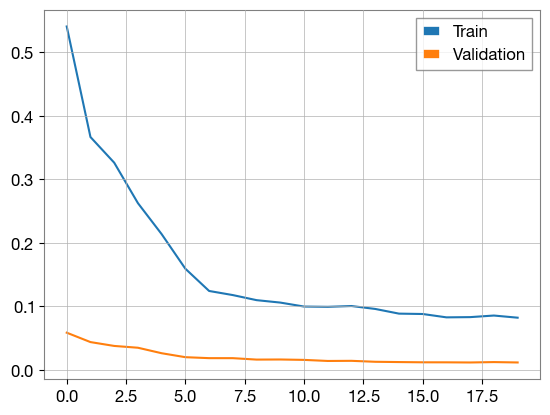

In [17]:
plt.plot(train_loss,label='Train')
plt.plot(valid_loss,label='Validation')
plt.legend()
plt.show()

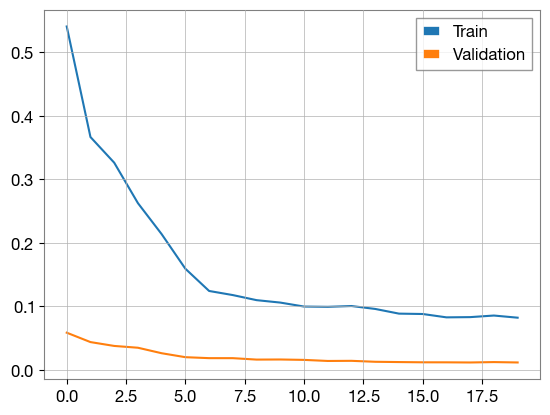

In [18]:
plt.plot(train_loss[-150:],label='Train')
plt.plot(valid_loss[-150:],label='Validation')
plt.legend()
plt.show()

In [19]:
from huggingface_hub import create_repo, upload_file
import os
import torch

hf_username = "Luca207"
model_name = "waveform_predictor_model_4.pt"

create_repo(f"{hf_username}/{model_name.split('.')[0]}", repo_type="model", exist_ok=True)
local_model_file = f"./{model_name}"
torch.save(waveform_predictor.state_dict(), local_model_file)

upload_file(
    path_or_fileobj=local_model_file,
    path_in_repo=model_name,
    repo_id=f"{hf_username}/{model_name.split('.')[0]}",
    repo_type="model"
)

print(f"Model state dictionary uploaded to https://huggingface.co/{hf_username}/{model_name.split('.')[0]}/blob/main/{model_name}")

os.remove(local_model_file)

Processing Files (1 / 1): 100%|██████████| 3.08MB / 3.08MB,  0.00B/s  
New Data Upload: |          |  0.00B /  0.00B,  0.00B/s  
No files have been modified since last commit. Skipping to prevent empty commit.


Model state dictionary uploaded to https://huggingface.co/Luca207/waveform_predictor_model_4/blob/main/waveform_predictor_model_4.pt


In [23]:
def inference(input,time_steps):
    input = input.unsqueeze(0)
    sos_token, sequence_start = waveform_predictor.parameters_encoder(input)
    sos_token = sos_token.unsqueeze(dim=1)
    sequence_start = sequence_start.unsqueeze(dim=1)
    window = torch.cat([sos_token, sequence_start], dim=1)
    output = []
    
    pad_mask = [[1.0,1.0]]

    # pwave = waveform_predictor.decode(window)[:,-1:,:]
    pwave = waveform_predictor.wave_decoder(sequence_start)[0][0][0].detach().cpu()#pwave[:,-1:,:]
    output.append(pwave)

    for t in tqdm(range(1,time_steps)):
        tmask = torch.tensor(pad_mask).to(device)
        pwave = waveform_predictor.decode(window,tmask)[:,-1:,:]
        window = torch.cat([window, pwave], dim=1)
        if window.shape[1] > hyperparameters['max_seq_len']:
            window = window[:,1:,:]

        pwave = waveform_predictor.wave_decoder(pwave[:,-1:,:])[0][0][0].detach().cpu()
        output.append(pwave)
        pad_mask[0].append(1.0)

    return output

100%|██████████| 9/9 [00:00<00:00, 25.74it/s]


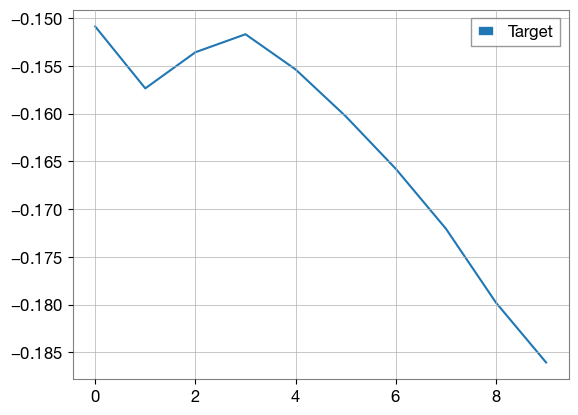

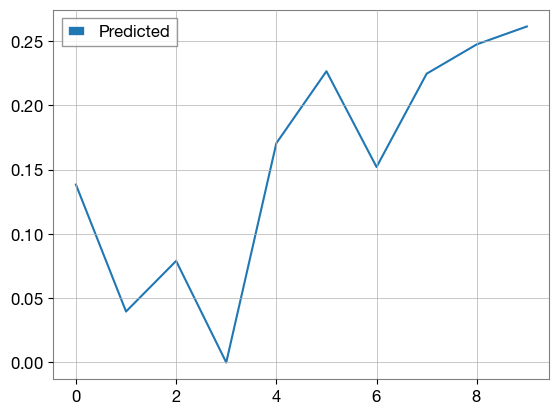

100%|██████████| 9/9 [00:00<00:00, 148.70it/s]


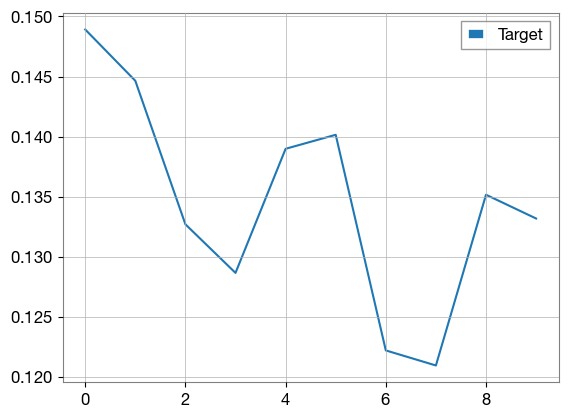

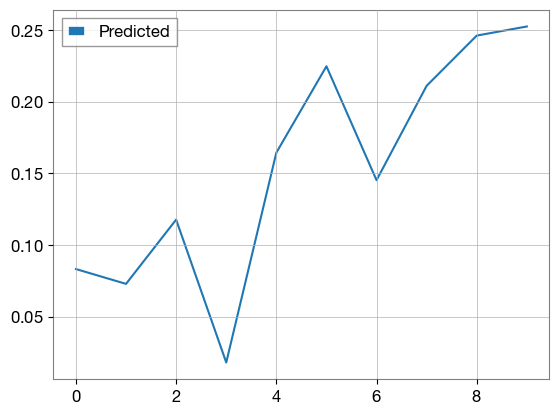

100%|██████████| 9/9 [00:00<00:00, 122.07it/s]


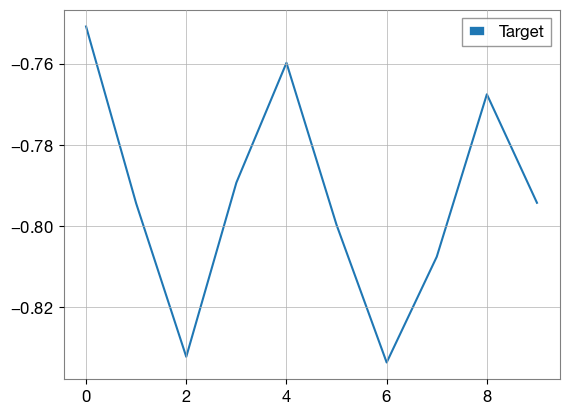

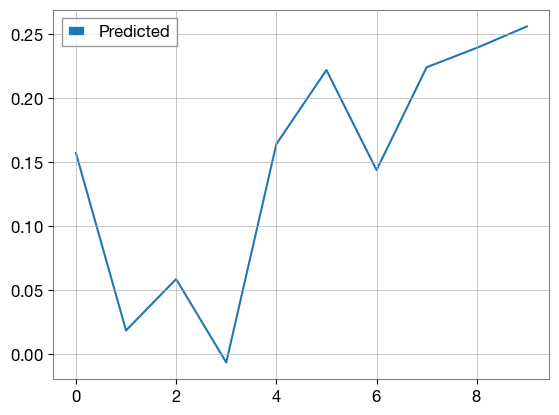

100%|██████████| 9/9 [00:00<00:00, 126.36it/s]


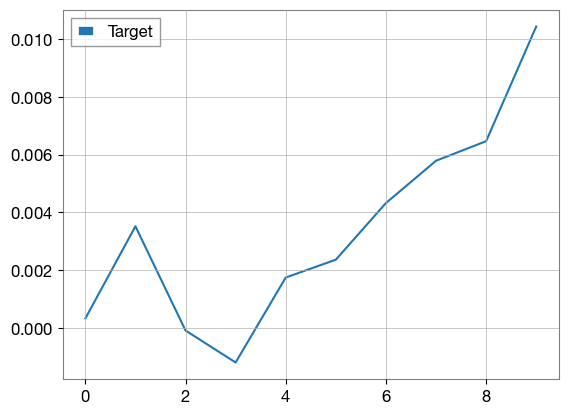

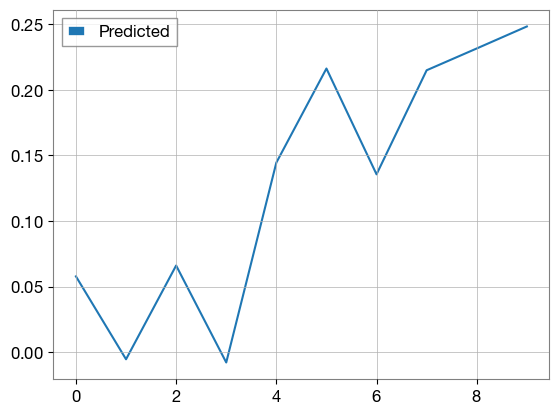

100%|██████████| 9/9 [00:00<00:00, 125.81it/s]


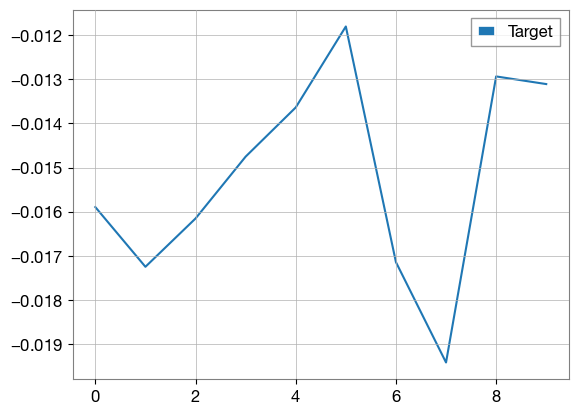

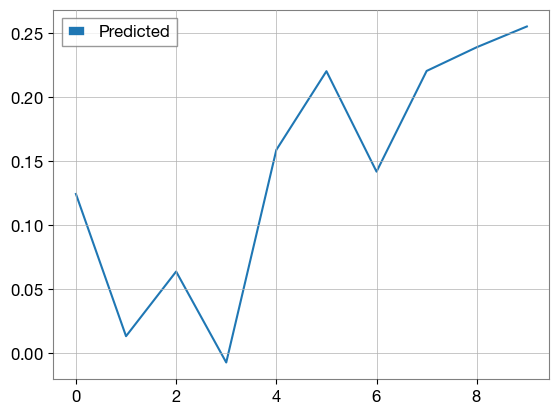

100%|██████████| 9/9 [00:00<00:00, 117.20it/s]


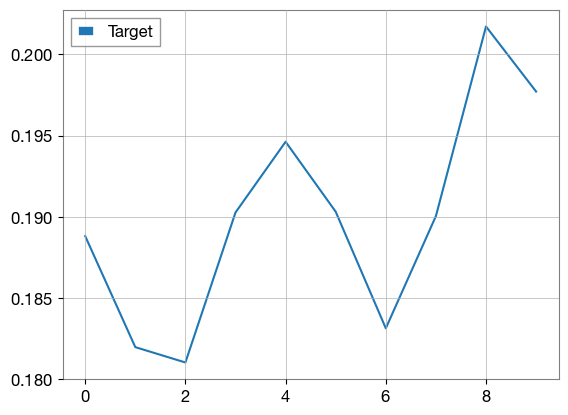

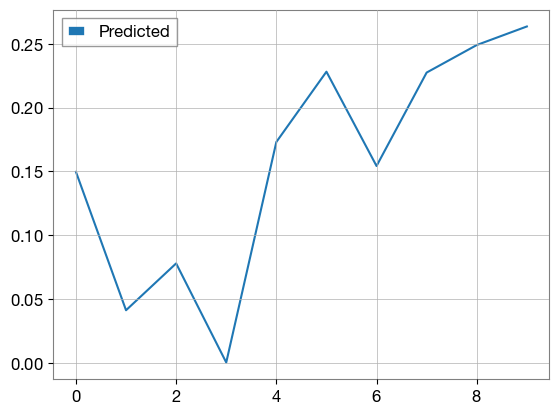

100%|██████████| 9/9 [00:00<00:00, 118.68it/s]


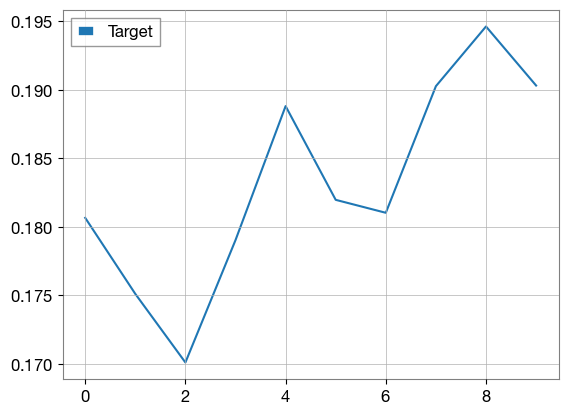

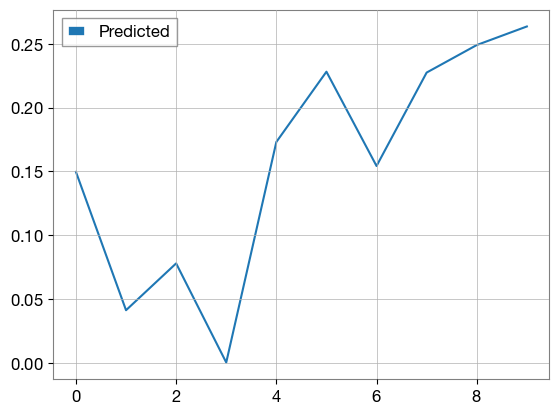

100%|██████████| 9/9 [00:00<00:00, 128.66it/s]


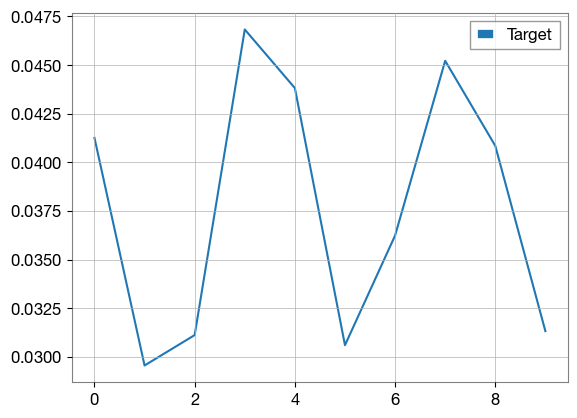

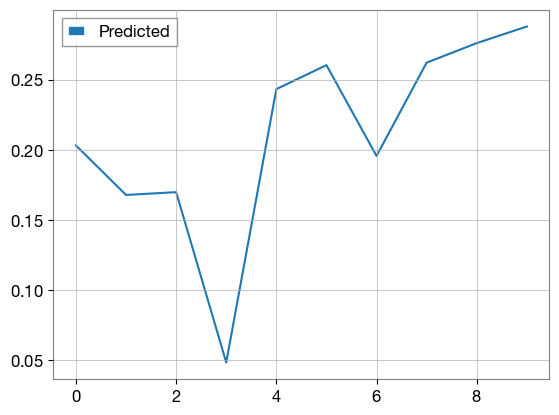

100%|██████████| 9/9 [00:00<00:00, 128.03it/s]


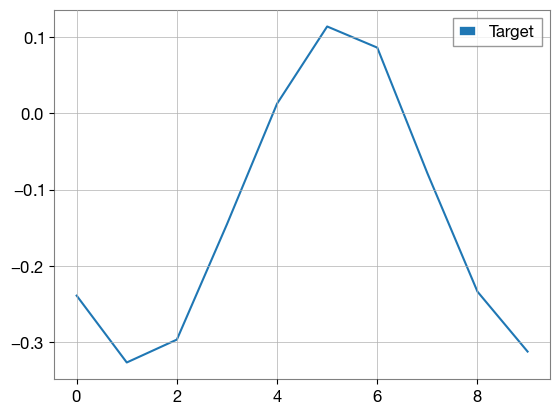

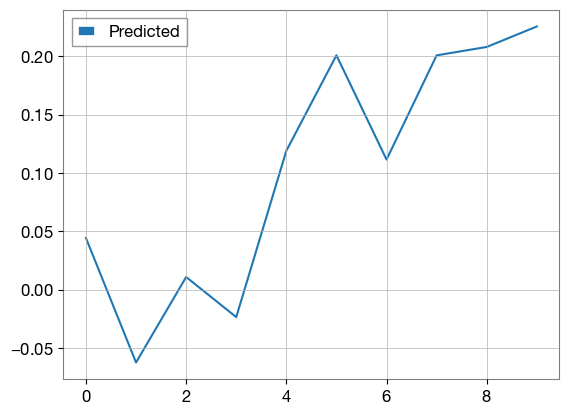

100%|██████████| 9/9 [00:00<00:00, 120.44it/s]


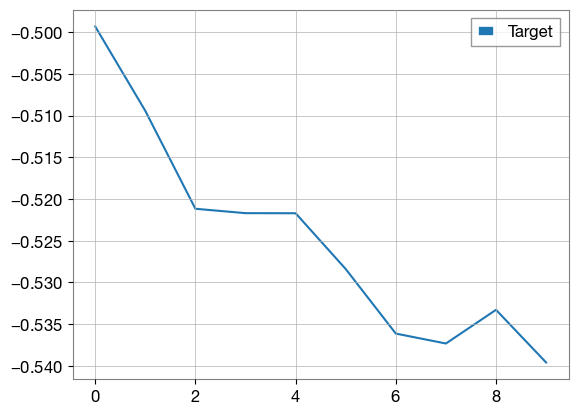

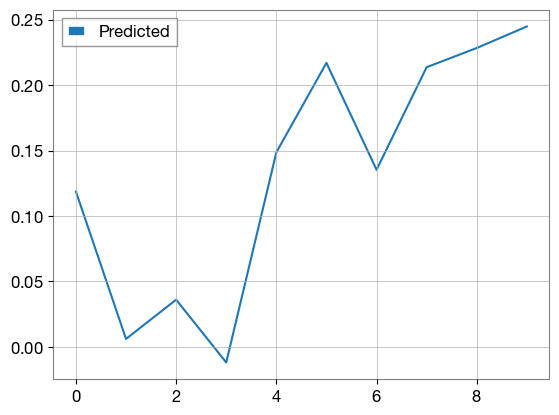

In [24]:
for id in range(10):
    wlen = 10

    waveform_predictor.eval()
    with torch.no_grad():
        output = inference(train_dataset[id][0],wlen)

    plt.plot(train_dataset[id][1][:wlen].cpu(),label='Target')
    plt.legend()
    plt.show()
    plt.plot(torch.tensor(output),label='Predicted')
    plt.legend()
    plt.show()

    print('\n\n\n')

# Fetch data

In [ ]:
event = 'GW230820_212515-v1'
start =-2# -3.7
end = 2#9

search_window = 0.1
frequency = 4096
search_window = int(search_window*frequency)

gps = event_gps(event)
segment = (int(gps + start) , int(gps + end) ) #(int(gps) - window_size, int(gps) + window_size)
wave_data = TimeSeries.fetch_open_data("H1", *segment, verbose=True, cache=True)

r = requests.get(
  f"https://gwosc.org//eventapi/json/event/{event.replace('-','/')}/",
  )
param_data = r.json()['events'][event]
strain_seg = wave_data.value

narr = np.array(wave_data)
vals = []
for i in range(0,narr.size,search_window):
  vals.append(np.abs(narr[i:i+search_window]).mean())

pos = np.argmax(vals)
hotspot = pos*search_window

arr = np.zeros(wave_data.size)
arr[pos*search_window:(pos+1)*search_window] = wave_data[pos*search_window:(pos+1)*search_window]

In [ ]:
event_data = {
    'waveform':[],
    'frequency':[],
    'time_window':[],
    'event_name': [],
    'version': [],
    'catalog.shortName': [],
    'GPS': [],
    'gracedb_id': [],
    'reference': [],
    'jsonurl': [],
    'mass_1_source': [],
    'mass_1_source_lower': [],
    'mass_1_source_upper': [],
    'mass_1_source_unit': [],
    'mass_2_source': [],
    'mass_2_source_lower': [],
    'mass_2_source_upper': [],
    'mass_2_source_unit': [],
    'network_matched_filter_snr': [],
    'network_matched_filter_snr_lower': [],
    'network_matched_filter_snr_upper': [],
    'network_matched_filter_snr_unit': [],
    'luminosity_distance': [],
    'luminosity_distance_lower': [],
    'luminosity_distance_upper': [],
    'luminosity_distance_unit': [],
    'chi_eff': [],
    'chi_eff_lower': [],
    'chi_eff_upper': [],
    'chi_eff_unit': [],
    'total_mass_source': [],
    'total_mass_source_lower': [],
    'total_mass_source_upper': [],
    'total_mass_source_unit': [],
    'chirp_mass_source': [],
    'chirp_mass_source_lower': [],
    'chirp_mass_source_upper': [],
    'chirp_mass_source_unit': [],
    'chirp_mass': [],
    'chirp_mass_lower': [],
    'chirp_mass_upper': [],
    'chirp_mass_unit': [],
    'redshift': [],
    'redshift_lower': [],
    'redshift_upper': [],
    'redshift_unit': [],
    'far': [],
    'far_lower': [],
    'far_upper': [],
    'far_unit': [],
    'p_astro': [],
    'p_astro_lower': [],
    'p_astro_upper': [],
    'p_astro_unit': [],
    'final_mass_source': [],
    'final_mass_source_lower': [],
    'final_mass_source_upper': [],
    'final_mass_source_unit': []
}

In [ ]:
catalogs = find_datasets(type="catalog")#['GWTC-4.0']#find_datasets(type="catalog")

start = -2
end = 2

search_window = 0.1
frequency = 4096
search_window = int(search_window*frequency)

for c_id in tqdm(range(len(catalogs))):
  try:
    ct = catalogs[c_id]
    gwtc_events = datasets.find_datasets(type='events', catalog=ct)

    print(f'Querying for catalog {ct}')
    for e_id in tqdm(range(len(gwtc_events))):
      event = gwtc_events[e_id]
      try:
        gps = event_gps(event)
        segment = (int(gps + start) , int(gps + end) ) #(int(gps) - window_size, int(gps) + window_size)
        wave_data = TimeSeries.fetch_open_data("H1", *segment, verbose=True, cache=True)

        r = requests.get(
          f"https://gwosc.org//eventapi/json/event/{event.replace('-','/')}/",
          )
        param_data = r.json()['events'][event]
        strain_seg = wave_data.value

        event_data['waveform'].append(np.array(wave_data))
        event_data['frequency'].append(frequency)
        event_data['time_window'].append(np.abs(end-start))
        event_data['event_name'].append(event)

        for p in list(event_data.keys())[4:]:
          event_data[p].append(param_data[p])


        # narr = np.array(wave_data)
        # vals = []
        # for i in range(0,narr.size,search_window):
        #   vals.append(np.abs(narr[i:i+search_window]).mean())

        # pos = np.argmax(vals)
        # hotspot = pos*search_window

        # arr = np.zeros(wave_data.size)
        # arr[pos*search_window:(pos+1)*search_window] = wave_data[pos*search_window:(pos+1)*search_window]

        # arr = np.array(wave_data)
        # n = arr.size
        # tick_locations = np.arange(0, n, frequency)
        # tick_labels = np.arange(0, n // frequency)
        # plt.axvline(hotspot,color='red',linewidth=4,alpha=0.3)
        # plt.plot(arr)
        # plt.xticks(tick_locations, tick_labels)
        # plt.xlabel("Seconds from time "+str(float(segment[0])) )
        # plt.show()
        # print('Name: ',param_data['commonName'])




        # print('\n\n')

      except:
        print(f'Error on event {event}')

  except:
      print(f'Error on catalog {ct}')

In [ ]:
from datasets import Dataset

hf_dataset = Dataset.from_dict(event_data)
print(hf_dataset)

In [ ]:
hf_dataset.push_to_hub("Luca207/waveforms")

In [ ]:

for id in range(1):
  wave = TimeSeries(
      event_data['waveform'][id],
      sample_rate=event_data['frequency'][id],
      epoch=event_data['GPS'][id]-event_data['time_window'][id]/2,
      name='H1:Test-Signal',
      unit='strain'
  )
  gps=event_data['GPS'][id]
  qgram = wave.q_transform(
      frange=(0, 1000),  # Narrowing the frequency can help
      qrange=(10, 120),
      outseg=(gps - 0.3, gps + 0.3) # CRITICAL: Centered on the official time
  )
  energy_over_time = np.sum(qgram.value, axis=0)
  time_index = np.argmax(energy_over_time)
  time_of_max_energy = qgram.times.value[time_index]
  index_in_waveform = np.argmin(np.abs(wave.times.value - time_of_max_energy))
  print(f'Event {event_data['event_name'][id]}')
  plot = qgram.plot(cmap='viridis', figsize=(10, 6))
  plot.colorbar(label="Normalized Energy")
  plt.yscale('log')
  plt.show()
  print('\n\n')


In [ ]:
print(f"Computing focused Q-transform centered on the official GPS time: {gps:.4f}")
gps=event_data['GPS'][0]
qgram = wave.q_transform(
    frange=(0, 1000),  # Narrowing the frequency can help
    qrange=(10, 120),
    outseg=(gps - 0.3, gps + 0.3) # CRITICAL: Centered on the official time
)
print("Q-transform complete.\n")


# --- 3. Find Precise Peak and Index ---
energy_over_time = np.sum(qgram.value, axis=0)
time_index = np.argmax(energy_over_time)
time_of_max_energy = qgram.times.value[time_index]
index_in_waveform = np.argmin(np.abs(wave.times.value - time_of_max_energy))

print("="*35)
print(f"Analysis Results for: {event}")
print(f"Data-driven Peak (Precise): {time_of_max_energy:.4f} GPS")
print(f"Corresponding index in waveform: {index_in_waveform}")
print("="*35 + "\n")


# --- 4. Plot the Results ---
print("Generating plot...")
plot = qgram.plot(cmap='viridis', figsize=(10, 6))
# ax = plot.axes[0]

# ax.set_title(f"Q-Transform for {event}")
# ax.set_yscale('log')
# ax.axvline(time_of_max_energy, color='red', linestyle='--', label='Precise Peak')
# ax.legend()
plot.colorbar(label="Normalized Energy")

plt.yscale('log')

plt.show()